##3.

Part a

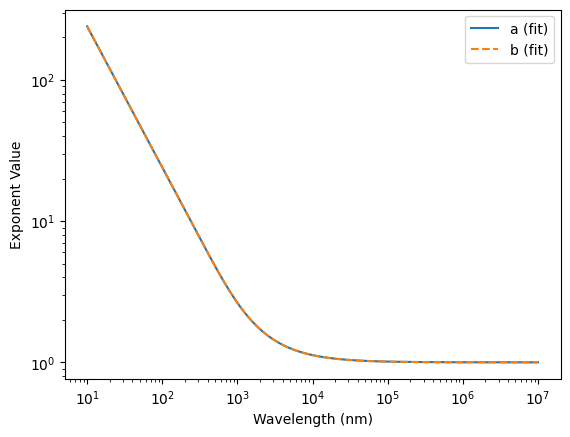

In [1]:
import numpy as np
import matplotlib.pyplot as plt

h, c, k_B = 6.626e-34, 2.998e8, 1.381e-23

lambda_nm = np.logspace(1, 7, 1000)
lam = lambda_nm * 1e-9              # meters
nu = c / lam                        # Hz

T = np.linspace(5990, 6010, 21)     # narrow window around 6000 K
lnT = np.log(T)

def lnB_nu(nu, T):
    x = h*nu/(k_B*T)
    return np.log(2*h*nu**3/c**2) - x - np.log1p(-np.exp(-x)) # Rewrite denominator so nothing overflows

def lnB_lam(lam, T):
    x = h*c/(lam*k_B*T)
    return np.log(2*h*c**2/lam**5) - x - np.log1p(-np.exp(-x))

# Need to define 2D arrays in order to get one value of B_nu/lambda per T
lnB_n = lnB_nu(nu[:, None], T[None, :])
lnB_l = lnB_lam(lam[:, None], T[None, :])

# polyfit fits each column separately, so pass (n_T, n_lam)
a = np.polyfit(lnT, lnB_n.T, 1)[0]
b = np.polyfit(lnT, lnB_l.T, 1)[0]

plt.plot(lambda_nm, a, label='a (fit)')
plt.plot(lambda_nm, b, '--', label='b (fit)')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Exponent Value')
plt.legend(); plt.show()

Part c

In [2]:
import numpy as np

max_lambda = 851

max_nu_lambda = 484

#interpolate values from what we know from the plot we made in part a
max_lambda_inter_a = np.interp(max_nu_lambda, lambda_nm, a)
max_nu_lambda_inter_b = np.interp(max_lambda, lambda_nm, b)

max_nu_lambda_inter_a = np.interp(max_lambda, lambda_nm, a)
max_lambda_inter_b = np.interp(max_nu_lambda, lambda_nm, b)


print(f"a value for for {max_lambda}nm: {max_nu_lambda_inter_a}")
print(f"a value for for {max_nu_lambda}nm: {max_lambda_inter_a}")
print(f"b value for for {max_nu_lambda}nm: {max_lambda_inter_b}")
print(f"b value for for {max_lambda}nm: {max_nu_lambda_inter_b}")


a value for for 851nm: 2.9963676573717923
a value for for 484nm: 4.988747871798252
b value for for 484nm: 4.988747871799519
b value for for 851nm: 2.9963676573715006


Part d

x value for for a=4: 611.5027975623566
x value for for b=4: 611.5027975626706


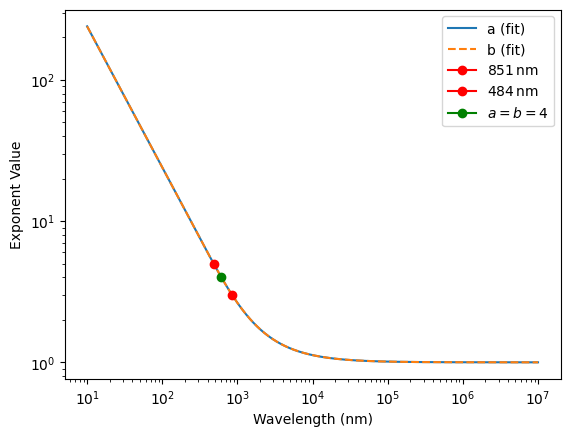

In [3]:
import numpy as np

#we know y=4, we want to now interpolate to find the corresponding x

#flip arrays in order to make a array increasing (inspired by Claude)
x_inter_a = np.interp(4, a[::-1], lambda_nm[::-1])
x_inter_b = np.interp(4, b[::-1], lambda_nm[::-1])

print(f"x value for for a=4: {x_inter_a}")
print(f"x value for for b=4: {x_inter_b}")

#Copy code for plotting in part a
plt.plot(lambda_nm, a, label='a (fit)')
plt.plot(lambda_nm, b, '--', label='b (fit)')

#Now overplot points from part c and d on the plot for a
plt.plot(max_lambda, max_nu_lambda_inter_b, marker='o', color='red', label=r'$851\,\text{nm}$')
plt.plot(max_nu_lambda, max_lambda_inter_a, marker='o', color='red', label=r'$484\,\text{nm}$')
plt.plot(x_inter_a, 4, marker='o', color='green', label=r'$a=b=4$')

#Make plot look pretty
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Wavelength (nm)'); plt.ylabel('Exponent Value')
plt.legend(); plt.show()


##4

Part c

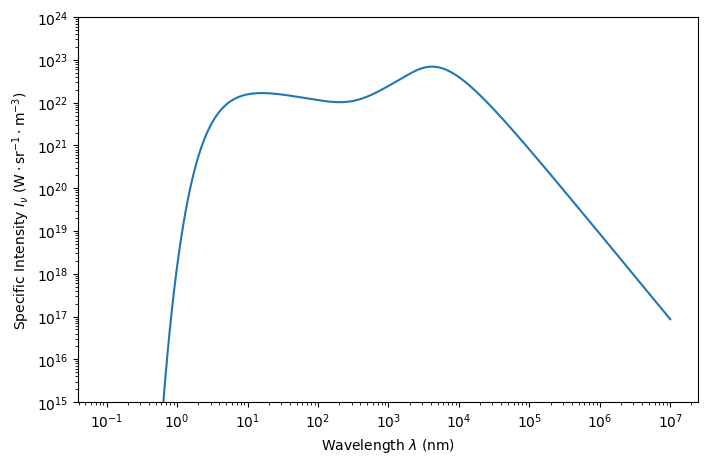

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

#define constants + given values
h = 6.626e-34
c = 3e8
k_B = 1.381e-23
T_in = 1e6
R_in = 1e11
R_out = 1e16

#Define wavelength array in nm (e.g., from 0.1 nm to 1e7 nm)
lambda_val = np.logspace(-1, 7, 500) # logspace is better for log-log plots

#Define multiplicative term outside integral (expressed in wavelength)
def mult_term_nu(nu):
    return 4*np.pi*h*nu**3 / c**2

#Define temperature function
def T(r):
  return T_in * (R_in/r)**(3/4) * (1+(r/np.sqrt(R_in * R_out))**2)**(1/8)

#Define integrand using substitution s = ln(r), so ds = dr/r -> r*dr = r^2*ds
def integrand(s, nu):
    r = np.exp(s)                       # s is ln(r)
    x = h * nu / (k_B * T(r))
    # Avoid division by zero or overflow inside exps
    if x > 700:
        return 0.0
    return r**2 * np.exp(-x) / (-np.expm1(-x))

# Integrate for each wavelength individually
intensities = []
for lam_nm in lambda_val:
    lam_m = lam_nm * 1e-9              # convert nm to meters
    nu = c / lam_m                   # convert to frequency (Hz)

    # Use logarithm limits for s = ln(r)
    integral_val, _ = quad(integrand, np.log(R_in), np.log(R_out), args=(nu,))

    # Calculate intensity
    intensities.append(mult_term_nu(nu) * integral_val)

#Plot stuff!
plt.figure(figsize=(8, 5))
plt.plot(lambda_val, intensities)
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e15,1e24)
plt.xlabel(r'Wavelength $\lambda$ (nm)')
plt.ylabel(r'Specific Intensity $I_{\nu}$ ($\text{W}\cdot\text{sr}^{-1}\cdot\text{m}^{-3}$)')
plt.show()

Part d

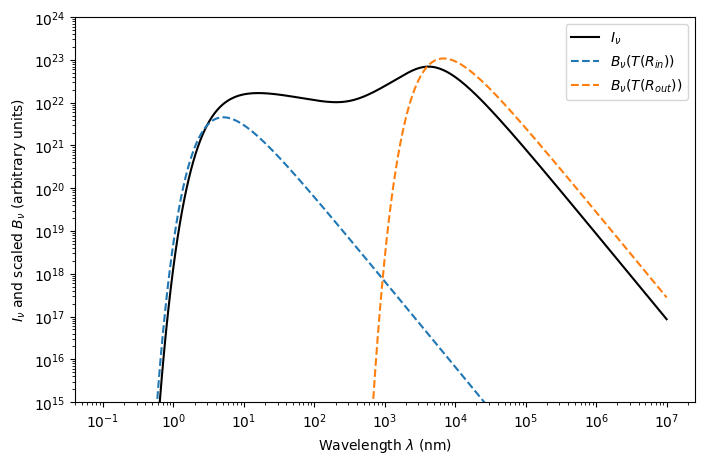

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

#define constants + given values
h = 6.626e-34
c = 3e8
k_B = 1.381e-23
T_in = 1e6
R_in = 1e11
R_out = 1e16

#Define wavelength array in nm
lambda_val = np.logspace(-1, 7, 500) # logspace

#Define multiplicative term outside integral (expressed in wavelength)
def mult_term_nu(nu):
    return 4*np.pi*h*nu**3 / c**2

#Define temperature function
def T(r):
  return T_in * (R_in/r)**(3/4) * (1+(r/np.sqrt(R_in * R_out))**2)**(1/8)

#Define integrand using substitution s = ln(r), so ds = dr/r -> r*dr = r^2*ds
def integrand(s, nu):
    r = np.exp(s)
    x = h * nu / (k_B * T(r))
    # Avoid division by zero or overflow inside exps
    if x > 700:
        return 0.0
    return r**2 * np.exp(-x) / (-np.expm1(-x))

# Integrate for each wavelength individually
intensities = []
for lam_nm in lambda_val:
    lam_m = lam_nm * 1e-9              # convert nm to meters
    nu = c / lam_m                   # convert to frequency (Hz)

    # Use logarithm limits for s = ln(r)
    integral_val, _ = quad(integrand, np.log(R_in), np.log(R_out), args=(nu,))

    # Calculate intensity
    intensities.append(mult_term_nu(nu) * integral_val)

#Make plots + functions for B_v(T) at R_in and R_out
def B_v(v, T):
    x = h * v / (k_B * T)
    return (2 * h * v**3 / c**2) * np.exp(-x) / (-np.expm1(-x))

#Convert lambda values into frequencies
lambda_vals = lambda_val * 1e-9
nu_vals = c / lambda_vals

#Scaling and plotting (with help from Claude)
I = np.array(intensities)

Bin  = B_v(nu_vals, T(R_in))
Bout = B_v(nu_vals, T(R_out))

# scale each to touch I_nu where it should dominate
i_in  = np.argmin(abs(lambda_val - 3))      # hot cutoff side
i_out = np.argmin(abs(lambda_val - 4e3))    # cool-ring bump

#Plot stuff!
plt.figure(figsize=(8, 5))
plt.plot(lambda_val, I, 'k', label=r'$I_\nu$')
plt.plot(lambda_val, Bin  * I[i_in]  / Bin[i_in],  '--', label=r'$B_\nu(T(R_{in}))$')
plt.plot(lambda_val, Bout * I[i_out] / Bout[i_out], '--', label=r'$B_\nu(T(R_{out}))$')
plt.xscale('log'); plt.yscale('log')
plt.ylim(1e15, 1e24)
plt.xlabel(r'Wavelength $\lambda$ (nm)')
plt.ylabel(r'$I_\nu$ and scaled $B_\nu$ (arbitrary units)')
plt.legend()
plt.show()